In [1]:
import sqlite3

import pandas as pd
from matplotlib import pyplot as plt
import matplotlib.ticker as mtick
import plotly.express as px
from matplotlib.container import BarContainer

conn = sqlite3.connect('threat_analyzer.db')
cursor = conn.cursor()


In [2]:
# Map setup
import json
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.collections import PatchCollection
from matplotlib.patches import PathPatch
from matplotlib.path import Path as MplPath   # aliased so it doesn't clash with pathlib.Path

# Natural Earth country boundaries as a plain GeoJSON file (about 3 MB).
MAP_URL = ("https://raw.githubusercontent.com/nvkelso/natural-earth-vector/"
           "master/geojson/ne_50m_admin_0_countries.geojson")
MAP_FILE = Path("world_countries_50m.geojson")   # cached next to the notebook after the first run


def load_world_shapes():
    """Return a list of (two_letter_country_code, matplotlib PathPatch), one per map feature."""
    if not MAP_FILE.exists():                          # download once, reuse afterwards (works offline)
        urllib.request.urlretrieve(MAP_URL, MAP_FILE)

    with open(MAP_FILE, encoding="utf-8") as f:
        features = json.load(f)["features"]

    shapes = []
    for feature in features:
        # ISO_A2 is "-99" for France and Norway in this file; ISO_A2_EH is the corrected column.
        code = feature["properties"]["ISO_A2_EH"]
        if code == "AQ":                               # skip Antarctica to save vertical space
            continue

        geometry = feature["geometry"]
        # A Polygon is a list of rings; a MultiPolygon is a list of those (islands, exclaves...)
        polygons = [geometry["coordinates"]] if geometry["type"] == "Polygon" else geometry["coordinates"]

        vertices, codes = [], []
        for polygon in polygons:
            for ring in polygon:                       # first ring = outline, any others = holes
                vertices.extend(ring)
                # pen instructions: move to the first point, draw lines through the rest, close the shape
                codes.extend([MplPath.MOVETO] + [MplPath.LINETO] * (len(ring) - 2) + [MplPath.CLOSEPOLY])

        shapes.append((code, PathPatch(MplPath(vertices, codes))))
    return shapes

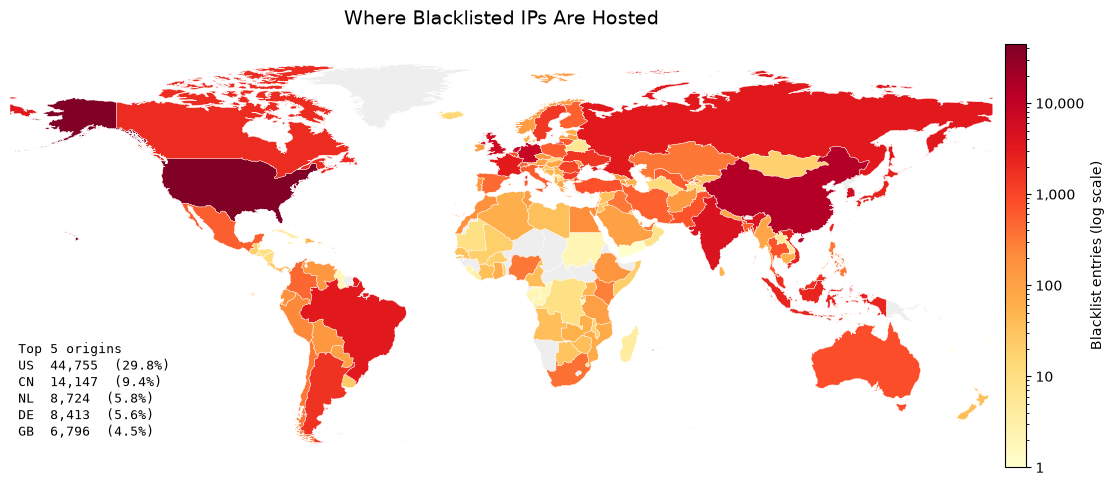

175 countries in data; 4 have no map shape (31 entries, 0.02% of total): BQ, GP, MQ, RE


In [4]:
# 1) Map builder

# 1. Query: how many blacklist entries per country?
df = pd.read_sql_query(
    "SELECT country_code, COUNT(*) AS cnt FROM blacklist_snapshots GROUP BY country_code",
    conn
)
counts = df.set_index("country_code")["cnt"]          # Series: country code -> count

# 2. Split the map shapes into countries we have data for and countries we don't
shapes = load_world_shapes()
with_data = [(code, patch) for code, patch in shapes if code in counts.index]
no_data   = [patch for code, patch in shapes if code not in counts.index]

# 3. Draw
fig, ax = plt.subplots(figsize=(12, 8))

# Countries with no blacklisted IPs: plain light grey
ax.add_collection(PatchCollection(no_data, facecolor="#eeeeee", edgecolor="white", linewidth=0.3))

# Countries with data: colour by count. LogNorm spreads the colours on a log scale; with a
# linear scale the US (~45,000) would swamp everything else and most countries would look identical.
norm = LogNorm(vmin=1, vmax=counts.max())

colored = PatchCollection([patch for _, patch in with_data],
                          cmap="YlOrRd", norm=norm, edgecolor="white", linewidth=0.3)
colored.set_array([counts[code] for code, _ in with_data])   # one value per shape, same order
ax.add_collection(colored)

# 4. Colour bar with plain-number labels instead of powers of ten
cbar = fig.colorbar(colored, ax=ax, shrink=0.55, pad=0.01)
ticks = [t for t in (1, 10, 100, 1_000, 10_000) if t <= counts.max()]
cbar.set_ticks(ticks)
cbar.set_ticklabels([f"{t:,}" for t in ticks])
cbar.set_label("Blacklist entries (log scale)")

# 5. Small "top 5" box in the empty South Pacific
top5 = counts.nlargest(5)
lines = ["Top 5 origins"] + [f"{code}  {n:,}  ({100 * n / counts.sum():.1f}%)" for code, n in top5.items()]
ax.text(-177, -54, "\n".join(lines), fontsize=9, va="bottom", family="monospace")

# 6. Frame: whole world, no axes, equal scaling so shapes aren't distorted
ax.set_xlim(-180, 180)
ax.set_ylim(-58, 85)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Where Blacklisted IPs Are Hosted", fontsize=14, pad=26, loc="center")
plt.tight_layout()
plt.show()

# 7. Sanity check: any country codes in the data that have no shape on the map?
missing = counts[~counts.index.isin({code for code, _ in shapes})]
print(f"{counts.shape[0]} countries in data; {missing.shape[0]} have no map shape "
      f"({missing.sum():,} entries, {100 * missing.sum() / counts.sum():.2f}% of total): "
      f"{', '.join(missing.index)}")

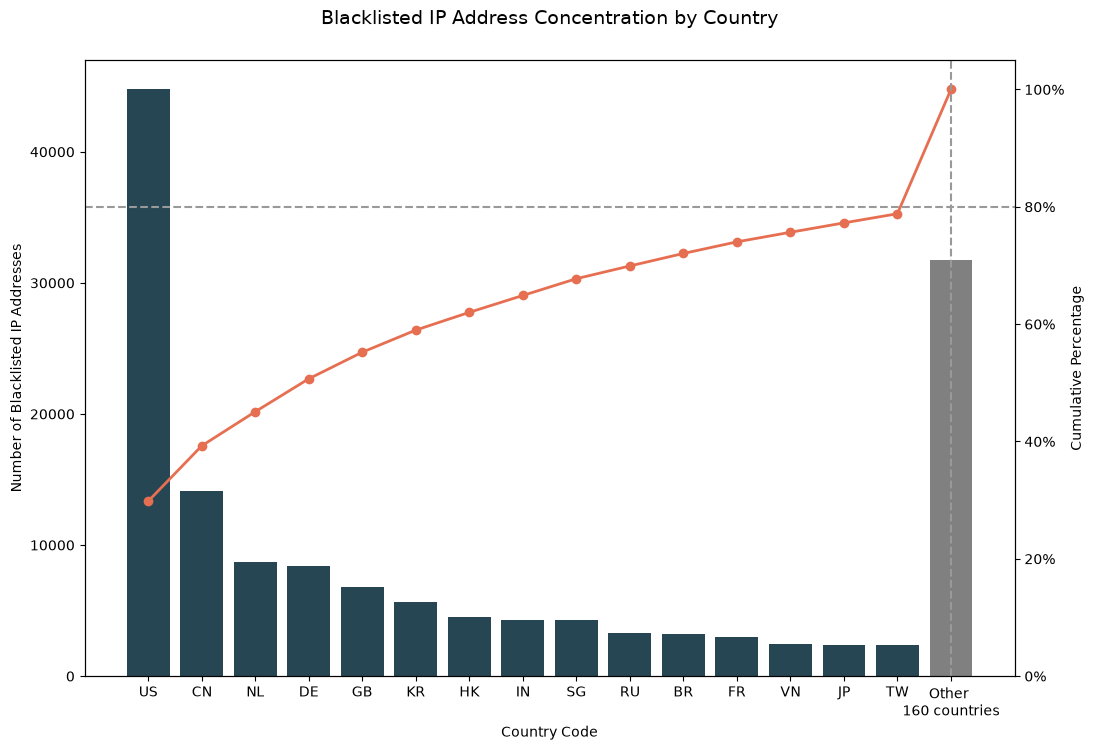

In [6]:
# 2) Pareto chart - Blacklisted IP Address concentration by country

df = pd.read_sql_query("SELECT country_code, COUNT(*) as cnt "
                       "FROM blacklist_snapshots "
                       "GROUP BY country_code "
                       "ORDER BY cnt DESC", conn)

top_n = 15
top = df.head(top_n)
other_count = df['cnt'].iloc[top_n:].sum()
other_row = pd.DataFrame({'country_code': [f'Other \n{len(df) - top_n} countries'], 'cnt': [other_count], 'tab': ['red']})
colors = ['#264653'] * top_n + ['gray']
df = pd.concat([top, other_row], ignore_index=True)
df["cumulative_pct"] = df.cnt.cumsum() / df.cnt.sum() * 100
cutoff_idx = df[df['cumulative_pct'] >= 80].index[0] #define cutoff percentage

#plot number amount of blacklisted IPs by country
fig, ax1 = plt.subplots(figsize=(12, 8))
ax1.bar(df['country_code'], df['cnt'], color=colors)
ax1.set_xlabel('Country Code')
ax1.set_ylabel('Number of Blacklisted IP Addresses')
ax1.set_title('Blacklisted IP Address Concentration by Country', fontsize=14, pad=26)

#plot cumulative percentage as we move through the chart
ax2 = ax1.twinx()
ax2.plot(df['country_code'], df['cumulative_pct'], color='#e76f51', marker="o", linewidth=2)
ax2.axhline(80, color='#999999', linestyle='--', linewidth=1.5)
ax2.axvline(cutoff_idx, color='#999999', linestyle='--', linewidth=1.5)
ax2.set_ylabel('Cumulative Percentage')
ax2.set_ylim(0, 105)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter())

#fig.savefig("pareto.png", transparent=True, textcolor="white")


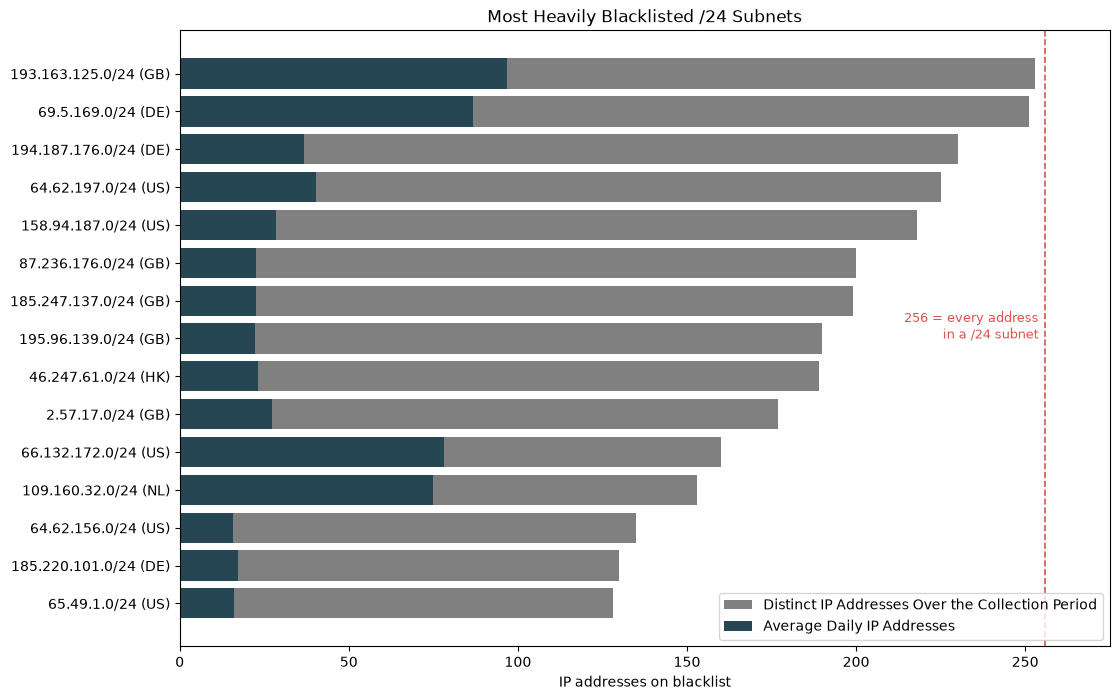

In [5]:
# 3) Horizontal Bar Chart - Most blacklisted subnets/IPs

df = pd.read_sql_query("SELECT ip_address, country_code, collected_at "
                       "FROM blacklist_snapshots", conn)

# select only IP addresses with 3 .'s (IPv4)
df = df[df['ip_address'].str.count(r'\.') == 3].copy()
# split final octet and append .0/24 to define subnets
df['subnet'] = df['ip_address'].str.rsplit('.', n=1).str[0] + '.0/24'

cumulative_count = df.groupby('subnet')['ip_address'].nunique().rename('cumulative_count') #distinct IP addresses
daily_count = df.groupby(['subnet', 'collected_at'])['ip_address'].nunique().reset_index()
avg_daily_count = daily_count.groupby('subnet')['ip_address'].mean().rename('avg_daily_count')

country = df.groupby('subnet')['country_code'].agg(lambda s: s.mode().iat[0]).rename('country')

top = (pd.concat([cumulative_count, avg_daily_count, country], axis=1)
       .sort_values('cumulative_count', ascending=False)
       .head(15))

top['label'] = top.index + ' (' + top['country'] + ')'
top = top.iloc[::-1]

fig, ax = plt.subplots(figsize=(12, 8))

ax.barh(top['label'], top['cumulative_count'], color='gray', label='Distinct IP Addresses Over the Collection Period')
ax.barh(top['label'], top['avg_daily_count'], color='#264653', label='Average Daily IP Addresses')

ax.axvline(256, color='#d9534f', linestyle='--', linewidth=1.2)
ax.text(254, 7.00, '256 = every address\n in a /24 subnet', color='#d9534f', ha='right', fontsize=9)

ax.set_xlim(0, 275)                    # leaves a little room past the 256 line
ax.set_xlabel('IP addresses on blacklist')
ax.set_title('Most Heavily Blacklisted /24 Subnets')
ax.legend(loc='lower right')
ax.grid(axis='y', visible=False)       # keep vertical gridlines, drop the horizontal ones


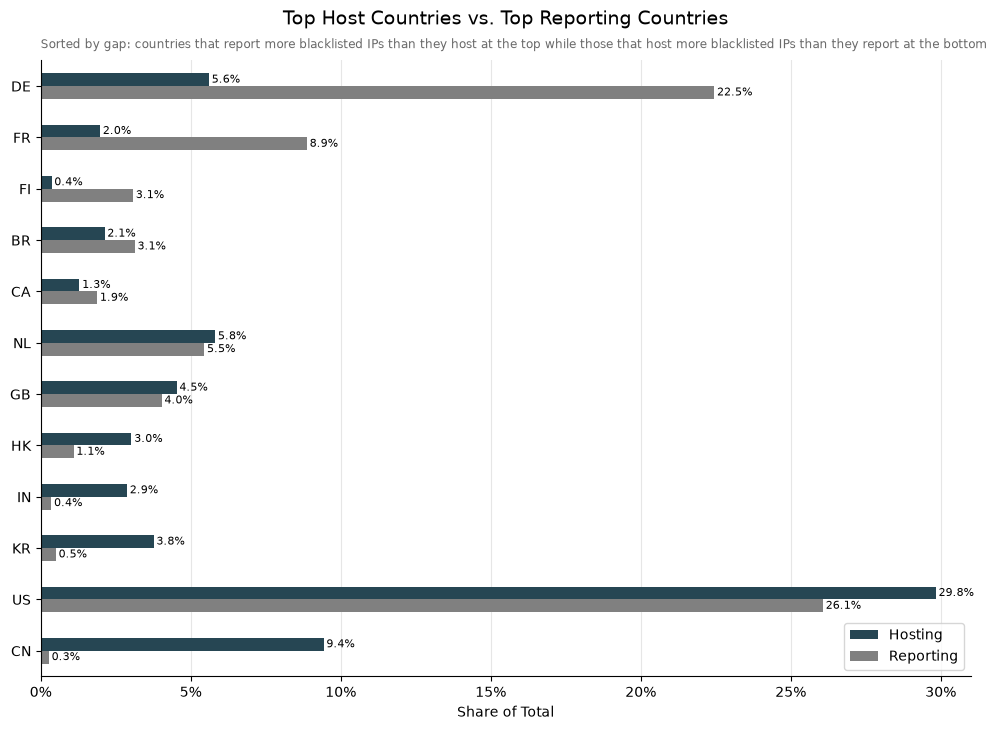

In [6]:
# 4) Horizontal Bar Chart Hosts vs Reports

# 2x queries. 1 each for reporter country and attack country of origin (host)
origin_country = pd.read_sql_query("SELECT country_code, COUNT(*) AS cnt "
                                   "FROM blacklist_snapshots "
                                   "GROUP BY country_code", conn).set_index('country_code')['cnt']

reporter_country = pd.read_sql_query("SELECT reporter_country_code AS country_code, COUNT(*) AS cnt "
                                     "FROM reports WHERE reporter_country_code IS NOT NULL "
                                     "GROUP BY reporter_country_code", conn).set_index('country_code')['cnt']

# Convert counts to % of total to make the numbers comparable. Replace NA or NaN values w/0
shares = pd.DataFrame({"Hosting": 100 * origin_country / origin_country.sum(),
                       "Reporting": 100 * reporter_country / reporter_country.sum()}).fillna(0)

top_n = 8
data = shares["Hosting"].nlargest(top_n).index.union(shares["Reporting"].nlargest(top_n).index)
df = shares.loc[data].copy()
# Country reports more than it hosts
df["gap"] = df["Reporting"] - df["Hosting"]
df = df.sort_values('gap', ascending=False)

ax = df[["Hosting", "Reporting"]].plot.barh(figsize=(12, 8), color=['#264653', 'gray'])
ax.invert_yaxis() # get largest gap on top of chart (barh puts largest at bottom default)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=2, fontsize=8)

ax.set_xlim(0, 31)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("Share of Total")
ax.set_ylabel("")
ax.set_title("Top Host Countries vs. Top Reporting Countries", loc='center', fontsize=14, pad=26)
ax.annotate("Sorted by gap: countries that report more blacklisted IPs than they host at the top while those that host more blacklisted IPs than they report at the bottom", xy=(0, 1.02), xycoords='axes fraction', fontsize=8.5, color="dimgrey")
ax.legend(loc='lower right')
ax.grid(axis="x", color="#e6e6e6")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)



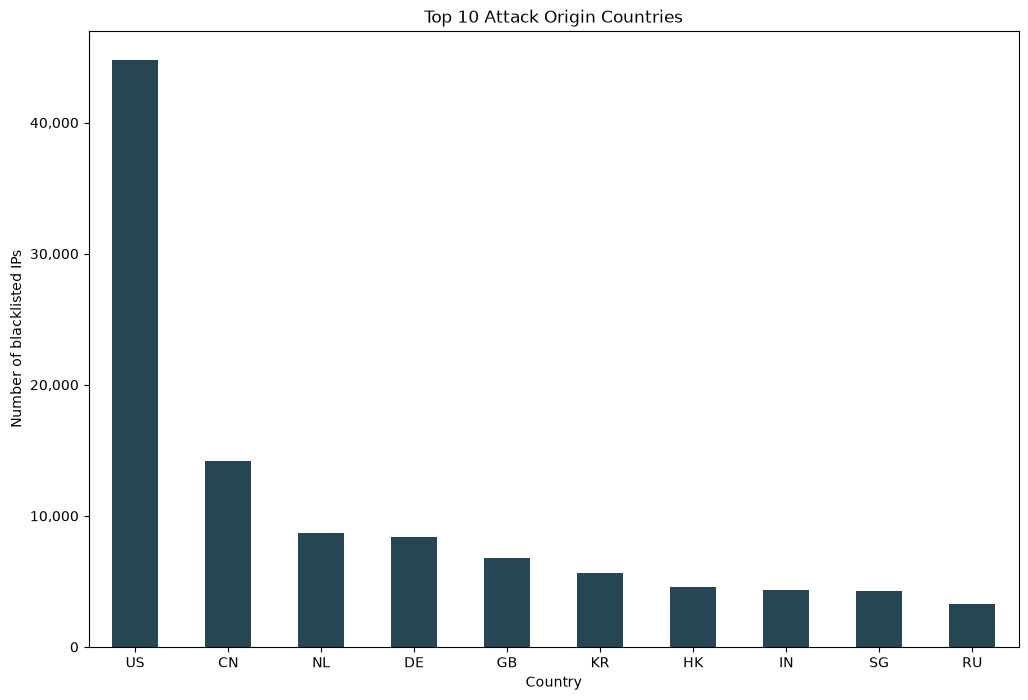

In [8]:
# Top 10 Attack Origin Countries

df = pd.read_sql_query("SELECT country_code, COUNT(*) as cnt "
                       "FROM blacklist_snapshots "
                       "GROUP BY country_code "
                       "ORDER BY cnt DESC "
                       "LIMIT 10", conn)

ax = df.plot(kind='bar', x='country_code', y='cnt',
             legend=False, color='#264653', figsize=(12, 8))

ax.set_xlabel("Country")
ax.set_ylabel("Number of blacklisted IPs")
ax.set_title("Top 10 Attack Origin Countries")
ax.tick_params(axis='x', rotation=0)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{int(x):,}'))


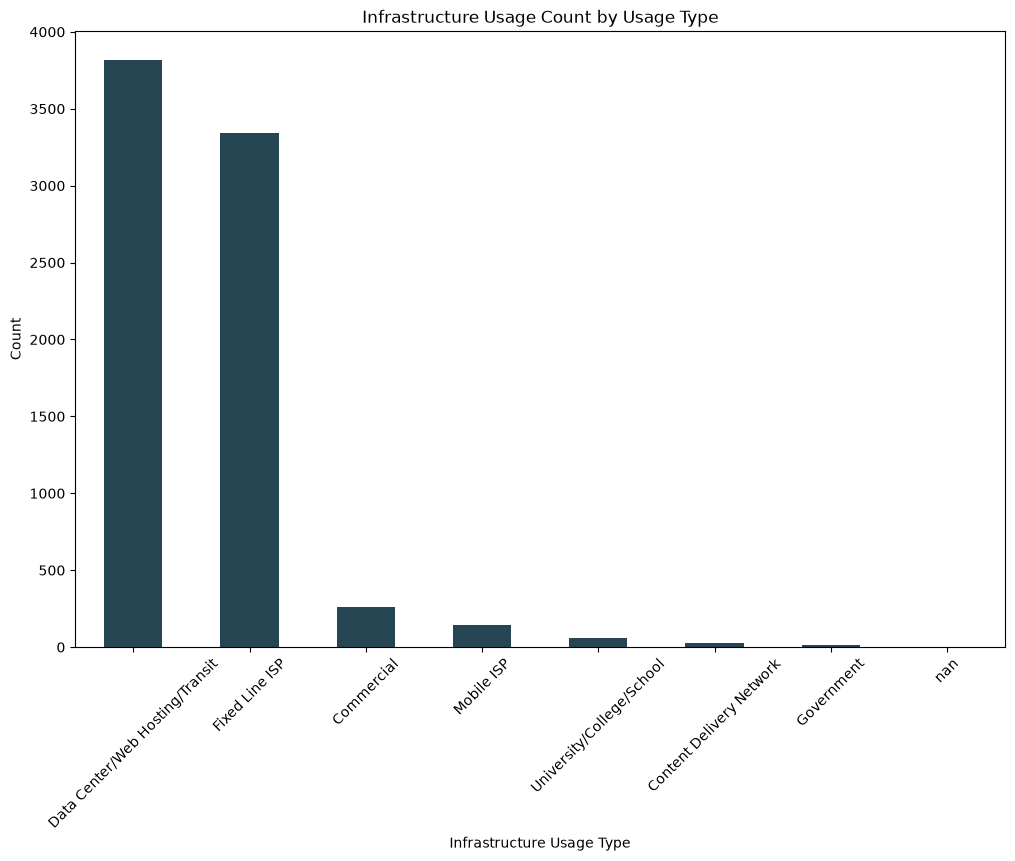

In [9]:
# Bar Chart - Infrastructure Type

df = pd.read_sql_query("SELECT usage_type, COUNT(*) as cnt "
                       "FROM ip_enrichment GROUP BY usage_type "
                       "ORDER BY cnt DESC", conn)

ax = df.plot(kind='bar', x='usage_type', y='cnt',
             legend=False, color='#264653', figsize=(12, 8))

ax.set_xlabel("Infrastructure Usage Type")
ax.set_ylabel("Count")
ax.set_title("Infrastructure Usage Count by Usage Type")
ax.tick_params(axis='x', rotation=45)
#ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{int(x):,}'))

In [11]:
#csv generator

df = pd.read_sql_query("SELECT usage_type, COUNT(*) as cnt "
                       "FROM ip_enrichment GROUP BY usage_type "
                       "ORDER BY cnt DESC", conn)

df.to_csv("InfrastructureUsageType.csv", index=False)